# 💧 Istanbul Dam Basins: Exploratory Data Analysis (EDA) & Statistical Modeling

This notebook explores daily precipitation across **Istanbul's 10 major dam basins** (`2011–2024`), overall reservoir occupancy rates (`2005–2021`), and urban daily water consumption trends.

### Table of Contents
1. **Dataset Loading & Overview**
2. **Dam Basin Precipitation Statistics (`2011–2024`)**
3. **Spatial Basin Clustering & Correlation Analysis**
4. **Critical Drought Periods (`<30%` Occupancy Threshold) Analysis**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid")

df_occ = pd.read_csv("../dam_occupancy.csv", parse_dates=["DATE"])
df_merged = pd.read_csv("../data/istanbul_baraj_birlesik_veri.csv", parse_dates=["Tarih"])
df_unpivot = pd.read_csv("../data/istanbul_baraj_yagis_unpivot.csv", parse_dates=["Tarih"])

print(f"Dam Occupancy Dataset (2005-2021): {df_occ.shape[0]:,} days")
print(f"Merged Rainfall & Consumption Dataset (2011-2024): {df_merged.shape[0]:,} days")
df_merged.head(5)

Dam Occupancy Dataset (2005-2021): 5,941 days
Merged Rainfall & Consumption Dataset (2011-2024): 4,797 days


,Tarih,Ömerli,Darlık,Elmalı,Terkos,Büyükçekmece,Sazlıdere,Alibey,Kazandere,Pabuçdere,Istrancalar,Gunluk_Tuketim_m3,Toplam_Yagis_mm,Ortalama_Yagis_mm,Doluluk_Orani_Yuzde,Rezerv_Su_Milyon_m3,Yil,Ay,Mevsim
0,2011-01-01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2096199,0.00,0.00,83.85,728.0,2011,1,Kış
1,2011-01-02,0.00,0.00,0.00,0.42,1.37,0.87,0.20,2.26,1.89,1.39,2214668,8.40,0.84,83.80,728.0,2011,1,Kış
2,2011-01-03,8.08,10.01,11.64,18.82,9.64,14.72,13.50,8.20,10.37,16.47,2092441,121.45,12.14,83.76,728.0,2011,1,Kış
3,2011-01-04,2.78,8.48,7.09,3.42,0.83,4.31,4.30,1.44,1.60,3.99,2096199,38.24,3.82,83.96,729.0,2011,1,Kış
4,2011-01-05,0.00,0.78,0.00,0.42,0.00,0.00,0.56,1.15,1.11,0.80,2214668,4.82,0.48,84.50,734.0,2011,1,Kış


## 1. Dam Basin Precipitation Statistics (2011–2024)
Summary of cumulative rainfall, annual average precipitation, daily mean/maximum rainfall, and rainy-day frequency (`>0.1 mm`) across all 10 dam basins:

In [2]:
dams = ["Ömerli", "Darlık", "Elmalı", "Terkos", "Büyükçekmece", "Sazlıdere", "Alibey", "Kazandere", "Pabuçdere", "Istrancalar"]

summary_df = pd.DataFrame({
    "Cumulative Rainfall (mm)": df_merged[dams].sum().round(1),
    "Annual Avg Rainfall (mm/yr)": (df_merged[dams].sum() / (len(df_merged) / 365.25)).round(1),
    "Daily Mean (mm)": df_merged[dams].mean().round(2),
    "Daily Max (mm)": df_merged[dams].max().round(2),
    "Rainy Days Ratio (%)": ((df_merged[dams] > 0.1).mean() * 100).round(1)
}).sort_values("Cumulative Rainfall (mm)", ascending=False)

summary_df

,Cumulative Rainfall (mm),Annual Avg Rainfall (mm/yr),Daily Mean (mm),Daily Max (mm),Rainy Days Ratio (%)
Kazandere,12469.7,949.5,2.60,170.20,27.4
Pabuçdere,11746.5,894.4,2.45,171.08,26.9
Istrancalar,11646.1,886.7,2.43,172.00,30.3
Terkos,11563.7,880.5,2.41,131.28,31.6
Darlık,10883.0,828.6,2.27,82.69,32.3
Ömerli,9952.1,757.8,2.07,123.53,29.8
Alibey,9682.3,737.2,2.02,119.00,30.1
Elmalı,9045.6,688.7,1.89,95.47,30.7
Sazlıdere,8734.2,665.0,1.82,178.25,27.9
Büyükçekmece,8057.2,613.5,1.68,95.59,27.3


## 2. Spatial Basin Clustering (Correlation Analysis)
Istanbul's dam basins form 3 distinct micro-climatic precipitation clusters:
- **Northwestern Black Sea Belt (`Kazandere`, `Pabuçdere`, `Istrancalar`):** Highest rainfall volume and strong intra-cluster correlation ($r > 0.84$).
- **Anatolian (Asian) Side Basins (`Ömerli`, `Darlık`, `Elmalı`):** Strong synchronous rainfall regime ($r \in [0.76, 0.82]$).
- **European Side Inner Basins (`Büyükçekmece`, `Sazlıdere`, `Alibey`):** High intra-cluster correlation ($r \in [0.74, 0.80]$).

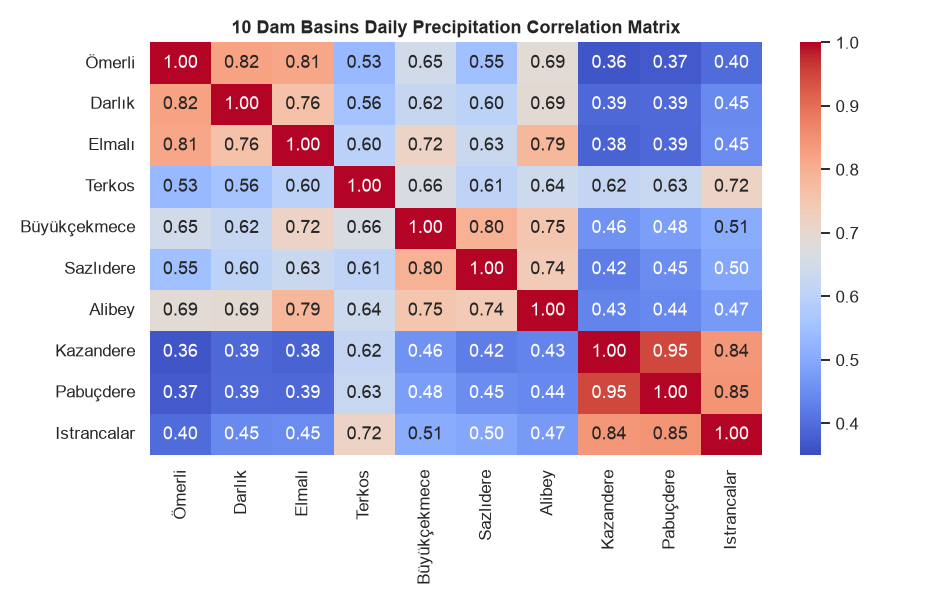

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 5.5), dpi=110)
corr = df_merged[dams].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=0.35, vmax=1.0, ax=ax)
ax.set_title("10 Dam Basins Daily Precipitation Correlation Matrix", fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Critical Drought Periods (<30% Occupancy Threshold)
Distribution of calendar days between `2005–2021` when overall reservoir occupancy fell below the critical **30% threshold**:

In [4]:
df_occ["Year"] = df_occ["DATE"].dt.year
drought_days = df_occ[df_occ["GENERAL_DAM_OCCUPANCY_RATE"] < 30]
drought_summary = drought_days.groupby("Year").agg(
    Critical_Days=("DATE", "count"),
    Min_Occupancy_Pct=("GENERAL_DAM_OCCUPANCY_RATE", "min"),
    Min_Reserved_Water_Mm3=("GENERAL_DAM_RESERVED_WATER", "min")
).sort_values("Critical_Days", ascending=False)

print(f"Total Critical Drought Days (<30%): {len(drought_days)} days ({len(drought_days)/len(df_occ)*100:.1f}% of the 2005-2021 period)")
drought_summary

Total Critical Drought Days (<30%): 638 days (10.7% of the 2005-2021 period)


,Critical_Days,Min_Occupancy_Pct,Min_Reserved_Water_Mm3
Year,,,
2008,210,15.72,137
2014,192,14.46,126
2007,159,9.20,80
2020,60,20.29,176
2021,17,19.16,166
